# Spectral signatures, advanced: the PROSAIL model, index saturation and LAI retrieval

[![Open in Google Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/OpenSkyLab-space/notebooks/blob/main/spectral_signatures_pro_en.ipynb)

**OpenSkyLab · notebook for the visual** [Spectral signatures](https://openskylab.space/edu_viz_spectral_signatures.html) · [česká verze](spectral_signatures_pro_cs.ipynb)

The advanced version of the spectral signatures notebook. The curves from the visual are computed here by a real radiative transfer model, PROSAIL, which couples leaf optics (PROSPECT) with the canopy (SAIL). You use it to show why NDVI saturates, build a table of simulations and from it estimate LAI for every pixel of two Sentinel-2 images near Roztoky, with its uncertainty and the places where the model fails.

**Goal:** find out which bands carry information on chlorophyll, water, dry matter and LAI, compare the saturation of NDVI, NDRE and CIre in the model, understand why inverting the model is ambiguous, and estimate LAI by inverting a table of simulations while knowing its limits.

**Data:** two Sentinel-2 L2A images of tile 33UVR (14 May and 21 July 2024) from the Earth Search catalogue on AWS, a 4 × 4 km window around Roztoky and Únětice; ESA WorldCover 2021 v200 classes. The simulations are computed by the `prosail` package (PROSPECT-5 and 4SAIL) inside the notebook. About 40 MB is downloaded; the simulation table takes 1 to 3 minutes. No ground LAI measurements exist for the window, so the inversion results are model estimates, not validated values.

**Tasks:** five. Write your answers in the *Your answer* cells below the tasks. Lines marked `# ◀ parameter` are meant to be changed; run the cell again with Shift + Enter.

**Time:** about 75 min. You need a Google account (Colab); nothing is installed on your computer. Run the cells in order from top to bottom.

## 1. Setup, two images and the model

In [1]:
%pip install -q rasterio prosail

Note: you may need to restart the kernel to use updated packages.


In [2]:
import requests, time, warnings
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
import rasterio, prosail
from rasterio.warp import reproject, Resampling
from pyproj import Transformer
from sklearn.neighbors import NearestNeighbors
warnings.filterwarnings("ignore")

STAC = "https://earth-search.aws.element84.com/v1/collections/sentinel-2-l2a/items/"
WORLDCOVER = "https://esa-worldcover.s3.eu-central-1.amazonaws.com/v200/2021/map/ESA_WorldCover_10m_2021_v200_N48E012_Map.tif"
BANDS = ["coastal", "blue", "green", "red", "rededge1", "rededge2", "rededge3", "nir", "nir08", "swir16", "swir22"]

def read_on_grid(url, grid, resampling=Resampling.bilinear, dtype=np.float32):
    """Read a cloud raster and resample it to grid = (transform, crs, height, width)."""
    tr, crs, ny, nx = grid
    out = np.zeros((ny, nx), dtype)
    with rasterio.Env(GDAL_DISABLE_READDIR_ON_OPEN="EMPTY_DIR", GDAL_HTTP_MAX_RETRY=5, GDAL_HTTP_RETRY_DELAY=2):
        with rasterio.open("/vsicurl/" + url) as src:
            reproject(rasterio.band(src, 1), out, dst_transform=tr, dst_crs=crs, resampling=resampling)
    return out

def s2_window(item_id, lon, lat, half):
    """Reflectance of all Sentinel-2 L2A bands in a square around a point (10 m grid in the tile's UTM)."""
    item = requests.get(STAC + item_id, timeout=60).json()
    epsg = item["properties"]["proj:epsg"] if "proj:epsg" in item["properties"] else int(item["properties"]["proj:code"].split(":")[1])
    x, y = Transformer.from_crs(4326, epsg, always_xy=True).transform(lon, lat)
    n = int(2 * half / 10)
    grid = (rasterio.transform.from_origin(x - half, y + half, 10, 10), f"EPSG:{epsg}", n, n)
    # since processing baseline 04.00 (2022) DN carry a +1000 offset; Earth Search has already removed it for newer items
    p = item["properties"]
    offset = -1000 if float(p.get("s2:processing_baseline", "0")) >= 4 and not p.get("earthsearch:boa_offset_applied", False) else 0
    refl = {b: (read_on_grid(item["assets"][b]["href"], grid) + offset) / 10000 for b in BANDS}
    scl = read_on_grid(item["assets"]["scl"]["href"], grid, Resampling.nearest, np.uint8)
    wl = {b: item["assets"][b]["eo:bands"][0]["center_wavelength"] for b in BANDS}
    return refl, scl, wl, grid, item

In [3]:
DATES = ["S2A_33UVR_20240514_0_L2A", "S2B_33UVR_20240721_0_L2A"]   # ◀ parameter: two images of one season (spring, summer)
LON, LAT, HALF = 14.375, 50.155, 2000                              # ◀ parameter: window centre and half width (m)
scenes = {}
for item_id in DATES:
    refl, scl, wl, grid, item = s2_window(item_id, LON, LAT, HALF)
    day = item["properties"]["datetime"][:10]
    scenes[day] = dict(refl=refl, clear=np.isin(scl, [4, 5, 6]), sza=90 - item["properties"]["view:sun_elevation"])
    print(f"{item_id}: cloud-free {scenes[day]['clear'].mean():.1%} of the window, solar zenith angle {scenes[day]['sza']:.1f}°")
DAYS = list(scenes)
wc = read_on_grid(WORLDCOVER, grid, Resampling.nearest, np.uint8)
CLASSES = {10: "forest", 30: "grassland", 40: "cropland", 50: "built-up", 80: "water"}

# bands for the model and their spectral response, approximated by a Gaussian from the centre and FWHM in the catalogue
INV = ["blue", "green", "red", "rededge1", "rededge2", "rededge3", "nir", "nir08", "swir16", "swir22"]
cwl = np.array([item["assets"][b]["eo:bands"][0]["center_wavelength"] for b in INV]) * 1000
fwhm = np.array([item["assets"][b]["eo:bands"][0]["full_width_half_max"] for b in INV]) * 1000
WL = np.arange(400, 2501)
SRF = np.exp(-0.5 * ((WL[None] - cwl[:, None]) / (fwhm[:, None] / 2.355)) ** 2)
SRF /= SRF.sum(1, keepdims=True)

def prosail_s2(cab=40, cw=0.012, cm=0.008, lai=3, ala=57, n=1.5, psoil=0.5, rsoil=1.0, sza=32, full=False):
    """Canopy reflectance from PROSAIL (PROSPECT-5 + 4SAIL): the full 400–2500 nm spectrum (full=True) or the Sentinel-2 bands.
    cab chlorophyll (µg/cm²), cw leaf water (cm), cm dry matter (g/cm²), lai leaf area index, ala mean leaf angle (°),
    n leaf structure, psoil fraction of dry soil, rsoil soil brightness; carotenoids = cab/4, view straight down."""
    r = prosail.run_prosail(n, cab, cab / 4, 0.0, cw, cm, lai=lai, lidfa=ala, hspot=0.01, tts=sza, tto=0.0, psi=0.0,
                            typelidf=2, rsoil=rsoil, psoil=psoil, factor="SDR")
    return r if full else SRF @ r

S2A_33UVR_20240514_0_L2A: cloud-free 99.2% of the window, solar zenith angle 32.9°


S2B_33UVR_20240721_0_L2A: cloud-free 98.8% of the window, solar zenith angle 31.5°


## 2. What the model does

PROSAIL computes canopy reflectance from leaf properties (chlorophyll `cab`, water `cw`, dry matter `cm`, structure `n`) and canopy properties (leaf area index `lai`, mean leaf angle `ala`, the soil below). The spectrum in 1 nm steps is converted to Sentinel-2 bands. The band spectral response is replaced here by a Gaussian, which is an approximation; ESA publishes the exact curves.

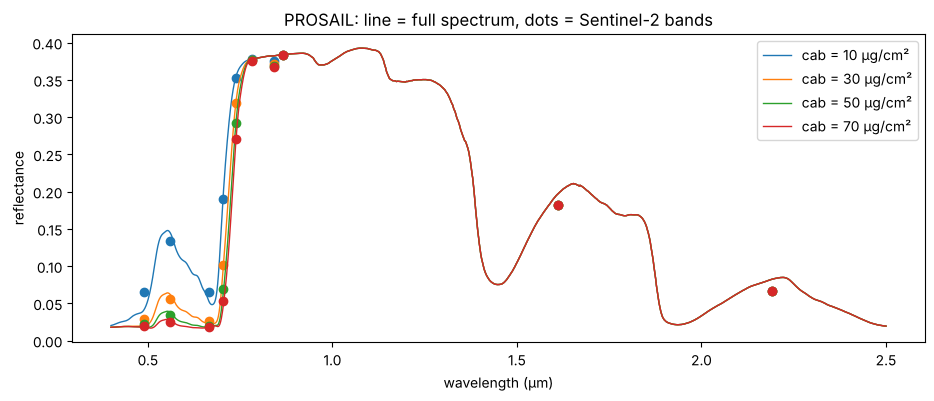

,blue,green,red,rededge1,rededge2,rededge3,nir,nir08,swir16,swir22
cab 20→60,-0.018,-0.051,-0.016,-0.072,-0.054,-0.001,-0.005,-0.000,0.000,0.000
cw 0.005→0.03,-0.000,-0.000,-0.000,-0.000,-0.002,-0.003,-0.006,-0.005,-0.131,-0.067
cm 0.004→0.012,-0.000,-0.001,-0.000,-0.005,-0.051,-0.078,-0.076,-0.080,-0.041,-0.025
lai 1→5,-0.037,-0.038,-0.054,-0.042,0.088,0.153,0.134,0.141,-0.076,-0.095
ala 40→70,-0.002,-0.009,0.005,-0.024,-0.122,-0.147,-0.139,-0.142,-0.045,-0.000


In [4]:
VAR, VALUES = "cab", [10, 30, 50, 70]      # ◀ parameter: variable (cab, cw, cm, lai, ala) and its values
UNITS = {"cab": "µg/cm²", "cw": "cm", "cm": "g/cm²", "lai": "m²/m²", "ala": "°"}
fig, ax = plt.subplots(figsize=(11, 4))
for v in VALUES:
    r = prosail_s2(**{VAR: v}, full=True)
    line, = ax.plot(WL / 1000, r, lw=1, label=f"{VAR} = {v} {UNITS[VAR]}")
    ax.plot(cwl / 1000, SRF @ r, "o", color=line.get_color())
ax.set(xlabel="wavelength (µm)", ylabel="reflectance", title="PROSAIL: line = full spectrum, dots = Sentinel-2 bands"); ax.legend(); plt.show()

# sensitivity: change in band reflectance when the variable goes from the lower to the higher value (others at default)
STEPS = {"cab": (20, 60), "cw": (0.005, 0.03), "cm": (0.004, 0.012), "lai": (1, 5), "ala": (40, 70)}
sens = pd.DataFrame({k: prosail_s2(**{k: hi}) - prosail_s2(**{k: lo}) for k, (lo, hi) in STEPS.items()}, index=INV).T
sens.index = [f"{k} {lo}→{hi}" for k, (lo, hi) in STEPS.items()]
sens.round(3)

> **✏️ Task 1.** Run the cell for `cab`, `cw`, `cm`, `lai` and `ala`. From the plots and the sensitivity table, say which Sentinel-2 bands carry information on chlorophyll, leaf water and LAI. Which two variables change the red edge and NIR almost equally but with opposite sign, and what does this mean for estimating LAI from one image?

*Your answer:* 

## 3. Index saturation in the model

We let LAI grow from 0 to 7 for three chlorophyll contents and follow NDVI, NDRE and CIre = NIR/RE1 − 1 (Gitelson et al. 2005). The table shows at what LAI the index reaches 90 % of the difference between bare soil and LAI 7, and how much a change in chlorophyll shifts the index, relative to that difference.

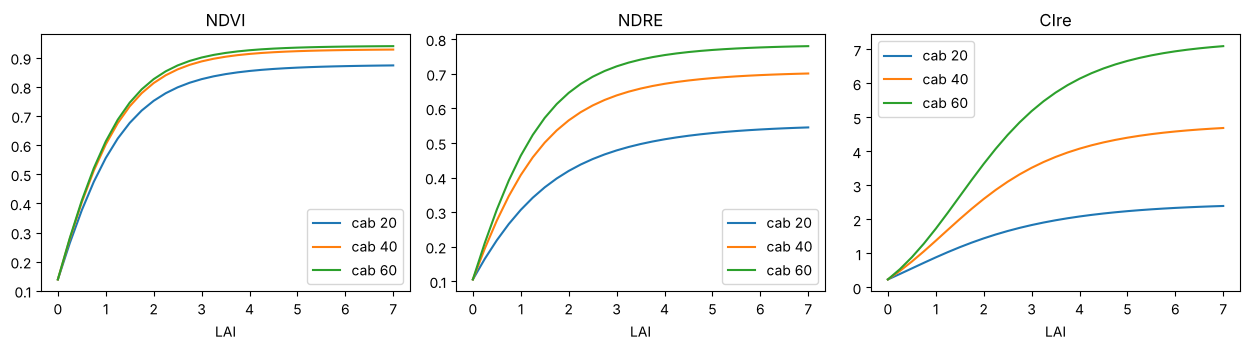

,LAI at 90 % (cab 20),LAI at 90 % (cab 40),LAI at 90 % (cab 60),effect of cab 20–60 at LAI 3
NDVI,2.75,2.50,2.5,0.09
NDRE,3.75,3.25,3.0,0.41
CIre,4.75,4.50,4.5,0.75


In [5]:
INDICES = {                                                            # ◀ parameter: indices; add your own, e.g. MTCI
    "NDVI": lambda b: (b["nir"] - b["red"]) / (b["nir"] + b["red"]),
    "NDRE": lambda b: (b["nir"] - b["rededge1"]) / (b["nir"] + b["rededge1"]),
    "CIre": lambda b: b["nir"] / b["rededge1"] - 1,
}
LAIS = np.arange(0, 7.01, 0.25)
CABS = [20, 40, 60]
sim = {cab: [dict(zip(INV, prosail_s2(cab=cab, lai=l))) for l in LAIS] for cab in CABS}
fig, ax = plt.subplots(1, len(INDICES), figsize=(4.2 * len(INDICES), 3.6))
rows = {}
for a, (name, f) in zip(ax, INDICES.items()):
    curves = {cab: np.array([f(b) for b in sim[cab]]) for cab in CABS}
    for cab, v in curves.items():
        a.plot(LAIS, v, label=f"cab {cab}")
        rel = (v - v[0]) / (v[-1] - v[0])                            # 0 = bare soil, 1 = LAI 7
        rows.setdefault(name, {})[f"LAI at 90 % (cab {cab})"] = LAIS[np.argmax(rel >= 0.9)]
    i3, v40 = list(LAIS).index(3.0), curves[40]
    rows[name]["effect of cab 20–60 at LAI 3"] = (curves[60][i3] - curves[20][i3]) / (v40[-1] - v40[0])
    a.set(xlabel="LAI", title=name); a.legend()
plt.tight_layout(); plt.show()
pd.DataFrame(rows).T.round(2)

> **✏️ Task 2.** At what LAI does NDVI saturate, and at what LAI NDRE and CIre? Why do red-edge indices saturate later? What price do they pay for it (last column)? Add your own index to `INDICES`, e.g. MTCI = (B6 − B5)/(B5 − B4), i.e. `(b["rededge2"] - b["rededge1"]) / (b["rededge1"] - b["red"])`, and place it among the others.

*Your answer:* 

## 4. A table of simulations and one pixel

The model cannot run backwards. So we run thousands of simulations with random variable values within given ranges, and for a pixel we look for those whose bands are most similar to the measured ones (smallest RMSE). The ranges are prior knowledge: what we know about the canopy in advance. For each image the table is computed with its solar elevation.

In [6]:
N_LUT = 20000                                                          # ◀ parameter: number of simulations in the table
RANGES = {"n": (1.2, 2.2), "cab": (10, 80), "cw": (0.002, 0.04), "cm": (0.002, 0.015),
          "lai": (0, 7), "ala": (30, 80), "psoil": (0, 1), "rsoil": (0.5, 1.5)}   # ◀ parameter: variable ranges (prior knowledge)
rng = np.random.default_rng(0)
lut = pd.DataFrame({k: rng.uniform(lo, hi, N_LUT) for k, (lo, hi) in RANGES.items()})
t0 = time.time()
LUT = {day: np.array([prosail_s2(sza=s["sza"], **p) for p in lut.to_dict("records")]) for day, s in scenes.items()}
print(f"{N_LUT} simulations for {len(DAYS)} images in {time.time() - t0:.0f} s")

20000 simulations for 2 images in 59 s


2024-05-14, point 14.3516, 50.1632: NDVI 0.83, best match RMSE 0.0082


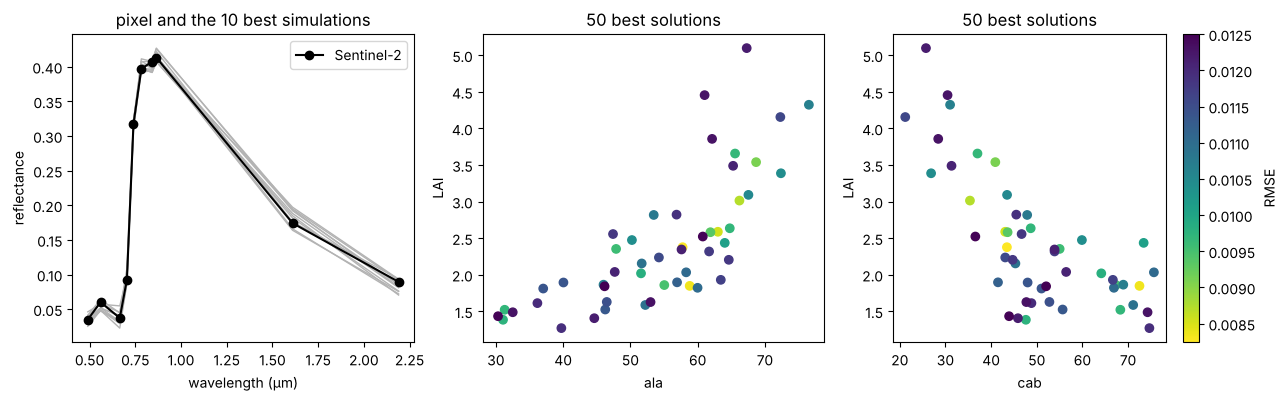

,5%,50%,95%,coefficient of variation
lai,1.417,2.219,4.248,0.370
cab,27.553,47.805,73.878,0.285
ccc,71.138,111.995,146.626,0.220
ala,31.842,56.894,70.665,0.213
cw,0.012,0.025,0.037,0.351


In [7]:
K = 50                                     # ◀ parameter: how many best solutions from the table to keep
PLON, PLAT = 14.3516, 50.1632              # ◀ parameter: point (field near Únětice); try forest 14.366, 50.148
day = DAYS[0]
x, y = Transformer.from_crs(4326, grid[1], always_xy=True).transform(PLON, PLAT)
col, row = [int(v) for v in ~grid[0] * (x, y)]
obs = np.array([scenes[day]["refl"][b][row, col] for b in INV])
rmse = np.sqrt(((LUT[day] - obs) ** 2).mean(1))
best = np.argsort(rmse)[:K]
sol = lut.iloc[best].assign(ccc=lambda d: d.lai * d.cab, rmse=rmse[best])
print(f"{day}, point {PLON}, {PLAT}: NDVI {(obs[6] - obs[2]) / (obs[6] + obs[2]):.2f}, best match RMSE {rmse[best[0]]:.4f}")
fig, ax = plt.subplots(1, 3, figsize=(15, 4))
for i in best[:10]:
    ax[0].plot(cwl / 1000, LUT[day][i], color="0.7", lw=1)
ax[0].plot(cwl / 1000, obs, "ko-", label="Sentinel-2"); ax[0].set(xlabel="wavelength (µm)", ylabel="reflectance", title="pixel and the 10 best simulations"); ax[0].legend()
for a, v in zip(ax[1:], ["ala", "cab"]):
    s = a.scatter(sol[v], sol.lai, c=sol.rmse, cmap="viridis_r"); a.set(xlabel=v, ylabel="LAI", title=f"{K} best solutions")
fig.colorbar(s, ax=ax[2], label="RMSE"); plt.show()
summary = sol[["lai", "cab", "ccc", "ala", "cw"]].describe(percentiles=[0.05, 0.5, 0.95]).T[["5%", "50%", "95%"]]
summary["coefficient of variation"] = sol[["lai", "cab", "ccc", "ala", "cw"]].std() / sol[["lai", "cab", "ccc", "ala", "cw"]].mean()
summary.round(3)

> **✏️ Task 3.** How wide is the LAI range among the best solutions and how does it relate to leaf angle and chlorophyll (plots on the right)? Compare the coefficient of variation of `lai`, `cab` and their product `ccc` (canopy chlorophyll, µg per cm² of ground). Why is the product better determined than either part? Try `K = 10` and `K = 200` and a forest point.

*Your answer:* 

## 5. LAI map and where the model does not fit

The same procedure for all pixels of the window. For each pixel we get the median LAI of the best solutions, their standard deviation as a measure of uncertainty, and the RMSE of the best simulation as a measure of how well the model explains the pixel at all.

inversion of 160000 pixels × 2 images in 13 s


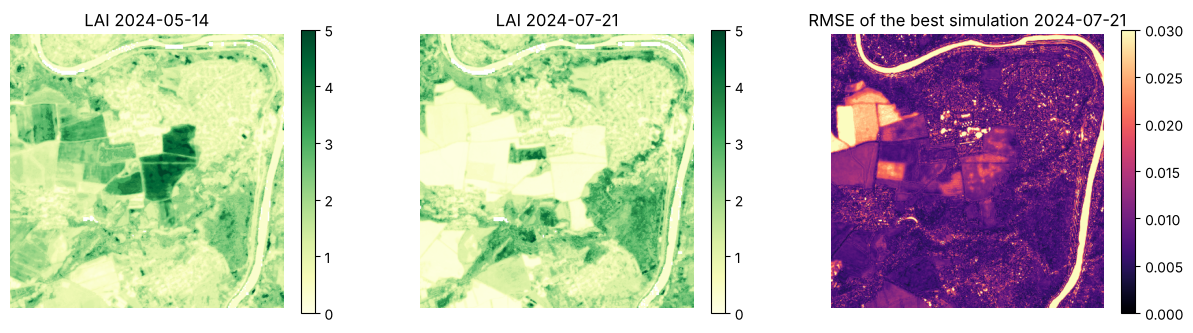

2024-05-14               2024-07-21              
                 lai lai_sd   rmse        lai lai_sd   rmse
forest         1.630  0.809  0.008      2.077  0.940  0.007
grassland      1.148  0.516  0.009      1.236  0.621  0.008
cropland       1.947  0.782  0.008      0.228  0.175  0.011
built-up       0.712  0.352  0.010      0.791  0.389  0.010
water          0.346  0.545  0.034      0.346  0.545  0.039

In [8]:
def invert(day, k=K):
    """For every pixel find the k simulations closest in reflectance (smallest RMSE) and return the median LAI, its spread, canopy chlorophyll content and RMSE."""
    X = np.dstack([scenes[day]["refl"][b] for b in INV]).reshape(-1, len(INV))
    d, idx = NearestNeighbors(n_neighbors=k).fit(LUT[day]).kneighbors(X)
    lai, cab = lut.lai.values[idx], lut.cab.values[idx]
    sh = wc.shape
    return dict(lai=np.median(lai, 1).reshape(sh), lai_sd=lai.std(1).reshape(sh),
                ccc=np.median(lai * cab, 1).reshape(sh), rmse=(d[:, 0] / np.sqrt(len(INV))).reshape(sh))

t0 = time.time()
inv = {day: invert(day) for day in DAYS}
print(f"inversion of {wc.size} pixels × {len(DAYS)} images in {time.time() - t0:.0f} s")
fig, ax = plt.subplots(1, 3, figsize=(15, 4.6))
for a, day in zip(ax, DAYS):
    im = a.imshow(np.where(scenes[day]["clear"], inv[day]["lai"], np.nan), cmap="YlGn", vmin=0, vmax=5); a.set_title(f"LAI {day}"); fig.colorbar(im, ax=a, shrink=0.8)
im = ax[2].imshow(inv[DAYS[-1]]["rmse"], cmap="magma", vmin=0, vmax=0.03); ax[2].set_title(f"RMSE of the best simulation {DAYS[-1]}"); fig.colorbar(im, ax=ax[2], shrink=0.8)
for a in ax: a.axis("off")
plt.show()
tab = pd.DataFrame({(day, q): {name: np.median(inv[day][q][scenes[day]["clear"] & (wc == code)]) for code, name in CLASSES.items()}
                    for day in DAYS for q in ["lai", "lai_sd", "rmse"]})
tab.round(3)

> **✏️ Task 4.** Where is the RMSE largest and why? Why does water get some LAI although there are no leaves, and why does built-up land fit almost as well as grassland? The forest comes out with LAI around 2, while a synthesis of ground measurements (Asner et al. 2003) gives a mean of 5.1 to 6.7 for temperate evergreen forests. Which assumptions of PROSAIL (one continuous layer of leaves, no trunks, gaps or crown shadows) contribute to the difference?

*Your answer:* 

## 6. LAI, NDVI and uncertainty in real data

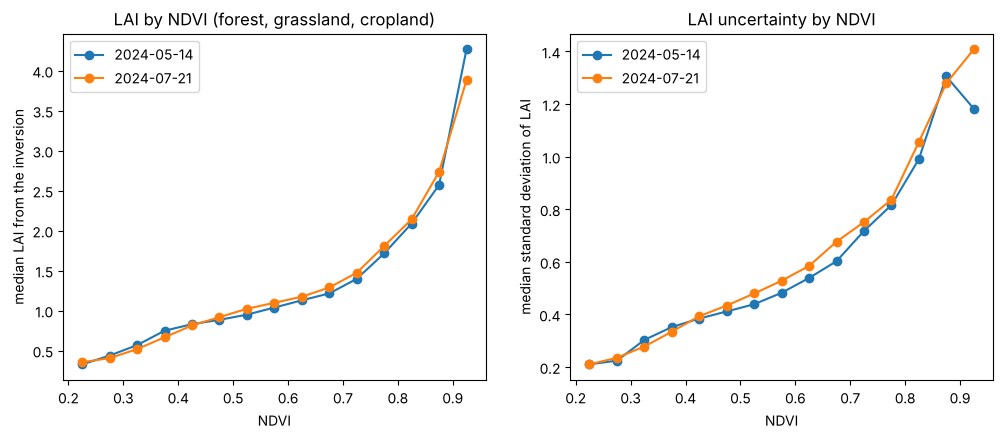

,NDVI 2024-05-14,NDVI 2024-07-21,LAI 2024-05-14,LAI 2024-07-21
forest,0.77,0.82,1.63,2.08
grassland,0.66,0.67,1.15,1.24
cropland,0.76,0.19,1.95,0.23


In [9]:
veg = np.isin(wc, [10, 30, 40])
fig, ax = plt.subplots(1, 2, figsize=(12, 4.5))
for day in DAYS:
    r = scenes[day]["refl"]; m = veg & scenes[day]["clear"]
    ndvi = ((r["nir"] - r["red"]) / (r["nir"] + r["red"]))[m]
    lai, sd = inv[day]["lai"][m], inv[day]["lai_sd"][m]
    bins = np.arange(0.2, 0.96, 0.05); k = np.digitize(ndvi, bins)
    mid = [(bins[i - 1] + bins[i]) / 2 for i in range(1, len(bins)) if (k == i).sum() > 50]
    ax[0].plot(mid, [np.median(lai[k == i]) for i in range(1, len(bins)) if (k == i).sum() > 50], "o-", label=day)
    ax[1].plot(mid, [np.median(sd[k == i]) for i in range(1, len(bins)) if (k == i).sum() > 50], "o-", label=day)
ax[0].set(xlabel="NDVI", ylabel="median LAI from the inversion", title="LAI by NDVI (forest, grassland, cropland)"); ax[0].legend()
ax[1].set(xlabel="NDVI", ylabel="median standard deviation of LAI", title="LAI uncertainty by NDVI"); ax[1].legend()
plt.show()
r0, r1 = scenes[DAYS[0]]["refl"], scenes[DAYS[1]]["refl"]
ndvi0, ndvi1 = [(r["nir"] - r["red"]) / (r["nir"] + r["red"]) for r in (r0, r1)]
both = scenes[DAYS[0]]["clear"] & scenes[DAYS[1]]["clear"]
pd.DataFrame({name: {"NDVI " + DAYS[0]: np.median(ndvi0[both & (wc == c)]), "NDVI " + DAYS[1]: np.median(ndvi1[both & (wc == c)]),
                     "LAI " + DAYS[0]: np.median(inv[DAYS[0]]["lai"][both & (wc == c)]), "LAI " + DAYS[1]: np.median(inv[DAYS[1]]["lai"][both & (wc == c)])}
              for c, name in CLASSES.items() if c in (10, 30, 40)}).T.round(2)

> **✏️ Task 5.** From what NDVI does the LAI uncertainty grow fastest, and how does this relate to the saturation in step 3? How did NDVI and LAI change between May and July on cropland, grassland and in the forest? Why would NDVI alone underestimate the difference between two dense canopies?

*Your answer:* 

> **✏️ Extension (optional).** Narrow the ranges in `RANGES` to what you know about the canopy (e.g. `ala` 50–65, `cab` 30–60) and run steps 4 to 6 again. How does the LAI uncertainty change? What happens when the prior knowledge is wrong, for example for a forest with a different leaf angle?

*Your answer:* 

---
### Data sources and references

- Copernicus Sentinel-2 data 2024, ESA (L2A, Sen2Cor); AWS Open Data registry (`sentinel-cogs`), Earth Search catalogue (Element 84). Free use with attribution.
- Zanaga, D. et al. (2022). *ESA WorldCover 10 m 2021 v200*. https://doi.org/10.5281/zenodo.7254221 (CC BY 4.0).
- Jacquemoud, S. et al. (2009). PROSPECT + SAIL models: A review of use for vegetation characterization. *Remote Sensing of Environment* 113, S56–S66. https://doi.org/10.1016/j.rse.2008.01.026
- Feret, J.-B. et al. (2008). PROSPECT-4 and 5: Advances in the leaf optical properties model separating photosynthetic pigments. *Remote Sensing of Environment* 112, 3030–3043. https://doi.org/10.1016/j.rse.2008.02.012
- Verhoef, W., Jia, L., Xiao, Q., Su, Z. (2007). Unified optical-thermal four-stream radiative transfer theory for homogeneous vegetation canopies. *IEEE Transactions on Geoscience and Remote Sensing* 45, 1808–1822. https://doi.org/10.1109/TGRS.2007.895844
- Gómez-Dans, J. *prosail*: Python bindings for PROSPECT and SAIL. https://github.com/jgomezdans/prosail
- Combal, B. et al. (2002). Retrieval of canopy biophysical variables from bidirectional reflectance using prior information to solve the ill-posed inverse problem. *Remote Sensing of Environment* 84, 1–15.
- Gitelson, A. A. et al. (2005). Remote estimation of canopy chlorophyll content in crops. *Geophysical Research Letters* 32, L08403. https://doi.org/10.1029/2005GL022688
- Asner, G. P., Scurlock, J. M. O., Hicke, J. A. (2003). Global synthesis of leaf area index observations: implications for ecological and remote sensing studies. *Global Ecology and Biogeography* 12, 191–205. https://doi.org/10.1046/j.1466-822X.2003.00026.x
- Pedregosa, F. et al. (2011). Scikit-learn: Machine Learning in Python. *Journal of Machine Learning Research* 12, 2825–2830.

### How to cite

OpenSkyLab (2026). Spectral signatures, advanced: the PROSAIL model, index saturation and LAI retrieval [notebook, teaching resource], version 1.0. https://github.com/OpenSkyLab-space/notebooks/blob/main/spectral_signatures_pro_en.ipynb. Licence CC BY 4.0.

Notebook text and code: OpenSkyLab, licence [CC BY 4.0](https://creativecommons.org/licenses/by/4.0/). Data are under their providers' licences (see above).

*This resource was developed by the OpenSkyLab team with the assistance of the generative AI Claude (Anthropic), used for drafting code and text. The authors are responsible for the content.*